In [1]:
import numpy as np
import xarray as xr
import pyproj
from pyresample.geometry import SwathDefinition
import pyresample.kd_tree as kd_tree
from pyresample import get_area_def
from glaciation_time_estimator.data_preprocessing.Resample_data import ProjectionTransformer
import matplotlib.pyplot as plt

In [2]:
ds = xr.load_dataset("/wolke_scratch/dnikolo/CLAAS_Data/np/2007/01/01/CTXin20070101121500405SVMSG01MD.nc")
aux_data = xr.load_dataset("/wolke_scratch/dnikolo/CLAAS_Data/np/CM_SAF_CLAAS3_L2_AUX.nc",decode_times=False)
var_field = ds["ctt"]

# Test projection transformation

In [139]:

import importlib
import glaciation_time_estimator.data_preprocessing.Resample_data as Rd
importlib.reload(Rd)

<module 'glaciation_time_estimator.data_preprocessing.Resample_data' from '/net/ch4/wolke_scratch/dnikolo/Glaciation_time_estimator/src/glaciation_time_estimator/data_preprocessing/Resample_data.py'>

In [140]:
transformer = Rd.ProjectionTransformer()
transformer.generate_lat_lon_prj(aux_data)

Bounds = [-79.74298161940857, 79.7396484770131, 26.044719326356088, 81.07635224475464]


In [141]:
var_field.isel(time=0).min()

/wolke_scratch/dnikolo/flex_trkr_env/lib/python3.11/site-packages/numba/np/ufunc/gufunc.py:171: RuntimeWarning: invalid value encountered in __numbagg_transformed_func
  return self.ufunc(*args, **kwargs)


<xarray.DataArray 'ctt' ()> Size: 4B
array(198.90001, dtype=float32)
Coordinates:
    time     datetime64[ns] 8B 2007-01-01T12:15:00

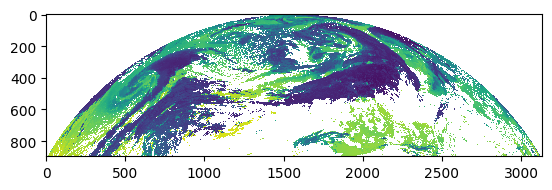

In [142]:
plt.imshow(var_field.isel(time=0),interpolation='none')

In [143]:
var_tyx.shape[1]*var_tyx.shape[0]
var_tyx

<xarray.DataArray 'ctt' (y: 896, x: 3133, time: 1)> Size: 11MB
array([[[nan],
        [nan],
        [nan],
        ...,
        [nan],
        [nan],
        [nan]],

       [[nan],
        [nan],
        [nan],
        ...,
        [nan],
        [nan],
        [nan]],

       [[nan],
        [nan],
        [nan],
        ...,
...
        ...,
        [nan],
        [nan],
        [nan]],

       [[nan],
        [nan],
        [nan],
        ...,
        [nan],
        [nan],
        [nan]],

       [[nan],
        [nan],
        [nan],
        ...,
        [nan],
        [nan],
        [nan]]], dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 8B 2007-01-01T12:15:00
  * x        (x) float64 25kB -0.1313 -0.1312 -0.1311 ... 0.1312 0.1313 0.1313
  * y        (y) float64 7kB 0.1513 0.1512 0.1511 ... 0.07642 0.07634 0.07626
Attributes:
    units:          K
    valid_range:    [   0 4060]
    standard_name:  air_temperature_at_cloud_top
    long_name:      Cloud Top Temperature
    grid_mapping:   projection
    cell_methods:   time: point

In [144]:
var_field

<xarray.DataArray 'ctt' (time: 1, y: 896, x: 3133)> Size: 11MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 8B 2007-01-01T12:15:00
  * x        (x) float64 25kB -0.1313 -0.1312 -0.1311 ... 0.1312 0.1313 0.1313
  * y        (y) float64 7kB 0.1513 0.1512 0.1511 ... 0.07642 0.07634 0.07626
Attributes:
    units:          K
    valid_range:    [   0 4060]
    standard_name:  air_temperature_at_cloud_top
    long_name:      Cloud Top Temperature
    grid_mapping:   projection
    cell_methods:   time: point

In [145]:
# result = transformer.remap_data(var_field,method="ewa")
var_tyx = var_field.transpose("time", "y", "x").load() 
# result_bil_raw = transformer.bilinear_remap(var_tyx.isel(time=0).load())

In [146]:
# plt.imshow(result_bil_raw,interpolation='none',cmap='rainbow')
# plt.colorbar()

In [149]:
# result = transformer.remap_data(var_field,method="ewa")
var_tyx = var_field.transpose("x", "y", "time").load() 
result_ewa = transformer.ewa_remap(var_tyx)

plt.imshow(np.flip(result_ewa,axis=0),vmin=198,interpolation='none')
plt.colorbar()

ValueError: ndarray is not C-contiguous

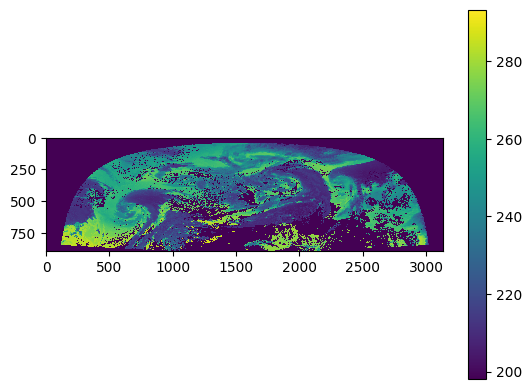

In [ ]:
# result = transformer.remap_data(var_field,method="ewa")
var_tyx = var_field.transpose("y", "x", "time").load() 
result_nn = transformer.nn_remap(var_tyx)

plt.imshow(np.flip(result_nn,axis=1)[0,:,:],vmin=198,interpolation='none')
plt.colorbar()

In [ ]:
# result_bil=result_bil[0,:,:]

In [ ]:
result_bil.shape

(896, 3133)

In [ ]:
result_bil=np.flip(result_bil_raw.values,axis=0)

In [ ]:
result_nn=result_nn[0,:,:]


/tmp/ipykernel_32425/3653466975.py:100: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(xx, yy, s=5, facecolors='none', edgecolors='k',


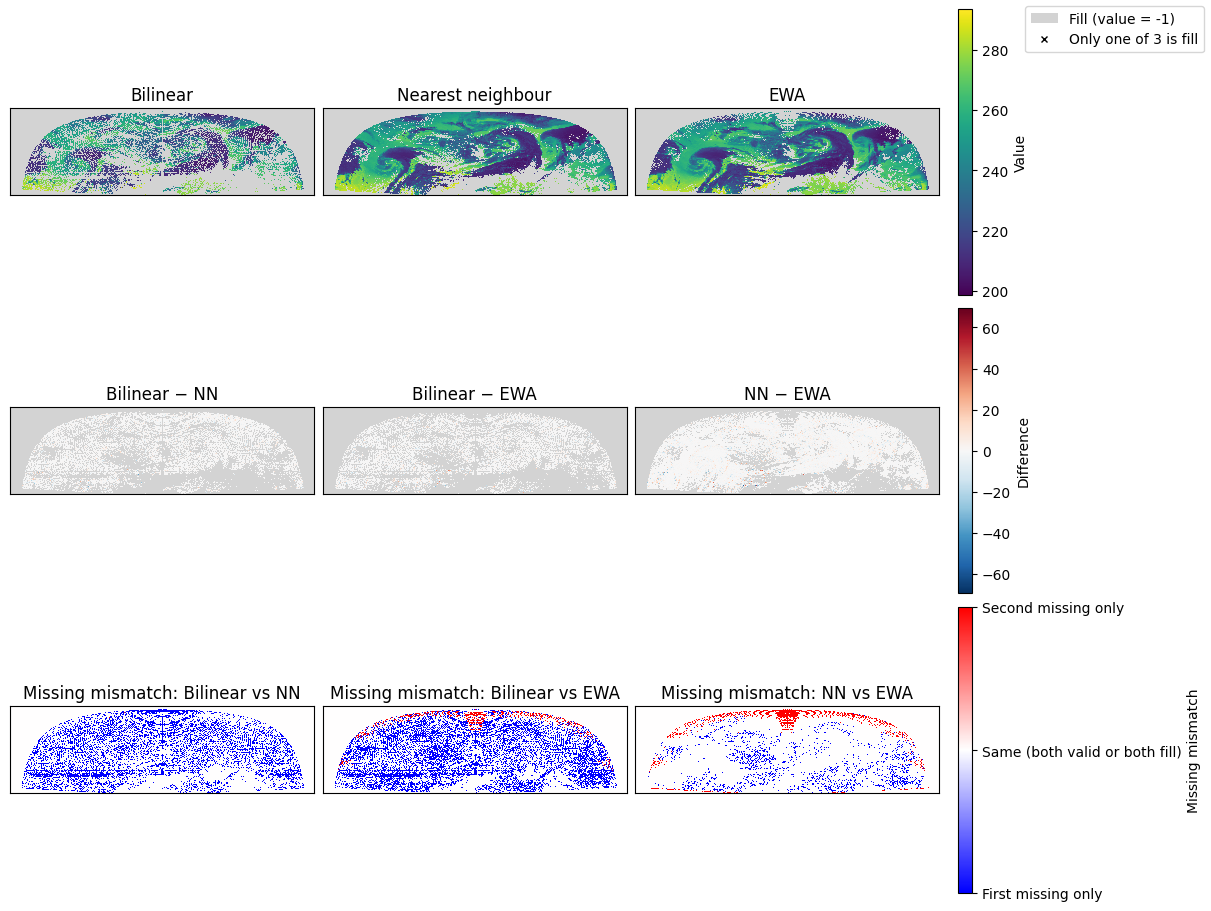

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fill_value = -1

# --- Helper: turn fill values into NaNs for plotting and diffs ---
def mask_fill(arr, fv=fill_value):
    arr = arr.astype(float)       # ensure we can store NaNs
    arr[arr == fv] = np.nan
    return arr

# Convert your results, replacing -1 with NaN
result_bil_plot = mask_fill(result_bil)
result_nn_plot  = mask_fill(result_nn)
result_ewa_plot = mask_fill(result_ewa)

# Pairwise differences (NaN wherever either input is fill)
diff_bil_nn  = result_bil_plot - result_nn_plot
diff_bil_ewa = result_bil_plot - result_ewa_plot
diff_nn_ewa  = result_nn_plot  - result_ewa_plot

# Common color scale for the original fields (ignore NaNs)
stack_orig = np.stack([result_bil_plot, result_nn_plot, result_ewa_plot])
vmin = np.nanmin(stack_orig)
vmax = np.nanmax(stack_orig)

# Symmetric color scale for differences
stack_diff = np.stack([diff_bil_nn, diff_bil_ewa, diff_nn_ewa])
diff_max = np.nanmax(np.abs(stack_diff))

# --- Masks for fill values ---
mask_bil = np.isnan(result_bil_plot)
mask_nn  = np.isnan(result_nn_plot)
mask_ewa = np.isnan(result_ewa_plot)

# Locations where exactly ONE of the three methods is fill
count_fill = mask_bil.astype(int) + mask_nn.astype(int) + mask_ewa.astype(int)
exactly_one_fill = (count_fill == 1)
yy, xx = np.where(exactly_one_fill)  # for overlay markers

# --- Colormaps: grey for fill (NaN) ---
cmap_data = plt.cm.viridis.copy()
cmap_data.set_bad('lightgrey')

cmap_diff = plt.cm.RdBu_r.copy()
cmap_diff.set_bad('lightgrey')

# --- Third row: pairwise "missing mismatch" maps ---
# Convention: -1 = first is missing only, +1 = second is missing only, 0 = no mismatch
def mismatch_map(mask_first, mask_second):
    m = np.zeros(mask_first.shape, dtype=float)
    m[mask_first & ~mask_second] = -1   # first missing, second valid
    m[mask_second & ~mask_first] = 1    # second missing, first valid
    # both missing or both valid -> 0
    return m

miss_bil_nn  = mismatch_map(mask_bil, mask_nn)
miss_bil_ewa = mismatch_map(mask_bil, mask_ewa)
miss_nn_ewa  = mismatch_map(mask_nn, mask_ewa)

cmap_miss = plt.cm.bwr.copy()
cmap_miss.set_bad('lightgrey')  # in case you later set some values to NaN

fig, axes = plt.subplots(3, 3, figsize=(12, 9), constrained_layout=True)

# --- Top row: the three remapped fields (NO interpolation in plotting) ---
im0 = axes[0, 0].imshow(result_bil_plot, origin='lower', interpolation='none',
                        vmin=vmin, vmax=vmax, cmap=cmap_data)
axes[0, 0].set_title('Bilinear')

im1 = axes[0, 1].imshow(result_nn_plot, origin='lower', interpolation='none',
                        vmin=vmin, vmax=vmax, cmap=cmap_data)
axes[0, 1].set_title('Nearest neighbour')

im2 = axes[0, 2].imshow(result_ewa_plot, origin='lower', interpolation='none',
                        vmin=vmin, vmax=vmax, cmap=cmap_data)
axes[0, 2].set_title('EWA')

# One colorbar for all original fields
cbar0 = fig.colorbar(im0, ax=axes[0, :], orientation='vertical',
                     fraction=0.02, pad=0.02)
cbar0.set_label('Value')

# --- Middle row: pairwise differences ---
im3 = axes[1, 0].imshow(diff_bil_nn, origin='lower', interpolation='none',
                        cmap=cmap_diff, vmin=-diff_max, vmax=diff_max)
axes[1, 0].set_title('Bilinear − NN')

im4 = axes[1, 1].imshow(diff_bil_ewa, origin='lower', interpolation='none',
                        cmap=cmap_diff, vmin=-diff_max, vmax=diff_max)
axes[1, 1].set_title('Bilinear − EWA')

im5 = axes[1, 2].imshow(diff_nn_ewa, origin='lower', interpolation='none',
                        cmap=cmap_diff, vmin=-diff_max, vmax=diff_max)
axes[1, 2].set_title('NN − EWA')

# Overlay markers where exactly one of the three methods is fill
for ax in axes[1, :]:
    ax.scatter(xx, yy, s=5, facecolors='none', edgecolors='k',
               linewidth=0.5, marker='x', label='Only one of 3 is fill')

# One colorbar for all difference plots
cbar1 = fig.colorbar(im3, ax=axes[1, :], orientation='vertical',
                     fraction=0.02, pad=0.02)
cbar1.set_label('Difference')

# --- Bottom row: pairwise "missing mismatch" plots ---
im6 = axes[2, 0].imshow(miss_bil_nn, origin='lower', interpolation='none',
                        cmap=cmap_miss, vmin=-1, vmax=1)
axes[2, 0].set_title('Missing mismatch: Bilinear vs NN')

im7 = axes[2, 1].imshow(miss_bil_ewa, origin='lower', interpolation='none',
                        cmap=cmap_miss, vmin=-1, vmax=1)
axes[2, 1].set_title('Missing mismatch: Bilinear vs EWA')

im8 = axes[2, 2].imshow(miss_nn_ewa, origin='lower', interpolation='none',
                        cmap=cmap_miss, vmin=-1, vmax=1)
axes[2, 2].set_title('Missing mismatch: NN vs EWA')

# One colorbar for all mismatch plots
cbar2 = fig.colorbar(im6, ax=axes[2, :], orientation='vertical',
                     fraction=0.02, pad=0.02)
cbar2.set_ticks([-1, 0, 1])
cbar2.set_ticklabels([
    'First missing only',
    'Same (both valid or both fill)',
    'Second missing only'
])
cbar2.set_label('Missing mismatch')

# Optional: remove axis ticks if you just want the patterns
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])

# Legend explaining fill and global mismatch markers
fill_patch = mpatches.Patch(facecolor='lightgrey', edgecolor='none',
                            label=f'Fill (value = {fill_value})')
mismatch_handle = plt.Line2D([], [], marker='x', linestyle='None',
                             markersize=5, markeredgecolor='k',
                             label='Only one of 3 is fill')
fig.legend(handles=[fill_patch, mismatch_handle], loc='upper right')

plt.show()


# Test other

In [ ]:
import os
import xarray as xr
import numpy as np
import subprocess
import time
import threading
from multiprocessing import Pool
from functools import partial
from glaciation_time_estimator.auxiliary_func.config_reader import read_config
from glaciation_time_estimator.auxiliary_func.Helper_fun import generate_temp_range
from glaciation_time_estimator.data_preprocessing.Resample_data import ProjectionTransformer
from glaciation_time_estimator.data_preprocessing.File_name_generator import generate_filename_dict
from glaciation_time_estimator.data_preprocessing.Output_file_generation import OutputResampledFile
import warnings

In [38]:
sat_data_cpp=xr.open_mfdataset("/wolke_scratch/dnikolo/CLAAS_Data/np/2021/01/02/CPPin2021010*.nc")

In [39]:
sat_data_cpp

<xarray.Dataset> Size: 25GB
Dimensions:                  (time: 96, y: 896, x: 3133, nx: 3133, ny: 896)
Coordinates:
  * time                     (time) datetime64[ns] 768B 2021-01-02 ... 2021-0...
  * x                        (x) float64 25kB -0.1313 -0.1312 ... 0.1312 0.1313
  * y                        (y) float64 7kB 0.1513 0.1513 ... 0.07638 0.0763
  * nx                       (nx) uint16 6kB 290 291 292 293 ... 3420 3421 3422
  * ny                       (ny) uint16 2kB 51 52 53 54 55 ... 943 944 945 946
Data variables: (12/30)
    cot_16                   (time, y, x) float32 1GB dask.array<chunksize=(1, 896, 1856), meta=np.ndarray>
    cot_16_unc               (time, y, x) float32 1GB dask.array<chunksize=(1, 896, 1856), meta=np.ndarray>
    cre_16                   (time, y, x) float32 1GB dask.array<chunksize=(1, 896, 1856), meta=np.ndarray>
    cre_16_unc               (time, y, x) float32 1GB dask.array<chunksize=(1, 896, 1856), meta=np.ndarray>
    cwp_16                   (time, y, x) float32 1GB dask.array<chunksize=(1, 896, 1856), meta=np.ndarray>
    cwp_16_unc               (time, y, x) float32 1GB dask.array<chunksize=(1, 896, 1856), meta=np.ndarray>
    ...                       ...
    platform_flag            (time) float32 384B dask.array<chunksize=(1,), meta=np.ndarray>
    subsatellite_lon         (time) float64 768B dask.array<chunksize=(1,), meta=np.ndarray>
    subsatellite_lat         (time) float64 768B dask.array<chunksize=(1,), meta=np.ndarray>
    subsatellite_alt         (time) float64 768B dask.array<chunksize=(1,), meta=np.ndarray>
    georef_offset_corrected  (time) int8 96B dask.array<chunksize=(1,), meta=np.ndarray>
    projection               (time) int8 96B 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0
Attributes: (12/45)
    filename:                                        CPPin20210102000000405SV...
    title:                                           ICDR of CM SAF CLoud pro...
    summary:                                         This file contains Cloud...
    comment:                                         Data in this file are st...
    creator_name:                                    DE/DWD
    creator_email:                                   contact.cmsaf@dwd.de
    ...                                              ...
    variable_id:                                     cwp,cot,cre,cdnc,cgt,cph
    id:                                              DOI:10.5676/EUM_SAF_CM/C...
    references:                                      https://doi.org/10.5676/...
    license:                                         The CM SAF data are owne...
    history:                                         Sun Dec  1 04:43:24 2024...
    NCO:                                             netCDF Operators version...

In [3]:
sat_data_cpp=xr.load_dataset("/wolke_scratch/dnikolo/CLAAS_Data/np/2021/01/02/CPPin20210102001500405SVMSGI1MD.nc")
sat_data_ctx=xr.load_dataset("/wolke_scratch/dnikolo/CLAAS_Data/np/2021/01/02/CTXin20210102001500405SVMSGI1MD.nc")
aux_data=xr.load_dataset("/wolke_scratch/dnikolo/CLAAS_Data/np/CM_SAF_CLAAS3_L2_AUX.nc",decode_times=False)

In [ ]:
class ProjectionTransformer():
    def __init__(self):
        self.AreaDef = None
        self.SwathDef = None
        self._neighbor_info = None
        self._neighbor_params = None  # (radius, epsilon, neighbours)

    def generate_lat_lon_prj(self, aux_data):
        lon_mat = aux_data["lon"][0, :, :].values
        lat_mat = aux_data["lat"][0, :, :].values

        self.bounds = [np.nanmin(lon_mat.astype(np.float64)),
                       np.nanmax(lon_mat.astype(np.float64)),
                       np.nanmin(lat_mat.astype(np.float64)),
                       np.nanmax(lat_mat.astype(np.float64))]
        print(f"Bounds = {self.bounds}")

        Proj4Args = (
            '+proj=eqc +lat_ts=0 +lat_0=0 +lon_0=0 +x_0=0 +y_0=0 '
            '+a=6378.137 +b=6378.137 +units=km'
        )
        Prj = pyproj.Proj(Proj4Args)
        AreaID = AreaName = ProjID = 'cyl'

        self.ny, self.nx = lon_mat.shape

        SW = Prj(self.bounds[0], self.bounds[2])
        NW = Prj(self.bounds[1], self.bounds[3])
        area_extent = [SW[0], SW[1], NW[0], NW[1]]

        self.AreaDef = get_area_def(AreaID, AreaName, ProjID, Proj4Args,
                                    self.nx, self.ny, area_extent)
        self.SwathDef = SwathDefinition(lons=lon_mat, lats=lat_mat)

        # Invalidate any old neighbor cache if geometry changed
        self._neighbor_info = None
        self._neighbor_params = None

        self._generate_new_coordinates()

    def _generate_new_coordinates(self):
        self.new_cord_lon = np.linspace(self.bounds[0], self.bounds[1], self.nx)
        self.new_cord_lat = np.linspace(self.bounds[2], self.bounds[3], self.ny)

    # --- New: build, use, and persist neighbor cache -------------------------

    def build_neighbor_cache(self, radius_of_influence=60000, epsilon=5, neighbours=1):
        """Precompute and cache neighbor info for later fast resampling."""
        if self.SwathDef is None or self.AreaDef is None:
            raise RuntimeError("Call generate_lat_lon_prj(...) before caching neighbors.")
        info = kd_tree.get_neighbour_info(
            self.SwathDef, self.AreaDef,
            radius_of_influence=radius_of_influence,
            neighbours=neighbours,
            epsilon=epsilon
        )
        self._neighbor_info = info
        self._neighbor_params = (radius_of_influence, epsilon, neighbours)

    def save_neighbor_cache(self, path):
        """Persist the cached neighbor info to disk."""
        if self._neighbor_info is None:
            raise RuntimeError("No neighbor cache to save. Call build_neighbor_cache() first.")
        vi, vo, ia, da = self._neighbor_info
        roi, eps, neigh = self._neighbor_params
        np.savez_compressed(path, vi=vi, vo=vo, ia=ia, da=da,
                            roi=roi, eps=eps, neigh=neigh,
                            nx=self.nx, ny=self.ny)

    def load_neighbor_cache(self, path):
        """Load neighbor info from disk (must match current geometry)."""
        z = np.load(path, allow_pickle=False)
        # Basic sanity checks
        if (int(z["nx"]) != self.nx) or (int(z["ny"]) != self.ny):
            raise ValueError("Cached neighbor grid size does not match current geometry.")
        self._neighbor_info = (z["vi"], z["vo"], z["ia"], z["da"])
        self._neighbor_params = (int(z["roi"]), int(z["eps"]), int(z["neigh"]))

    # -------------------------------------------------------------------------

    def remap_data(self, var_field, n_resample_procs=8,
                   radius_of_influence=60000, epsilon=5):
        if self.SwathDef is None:
            raise RuntimeError(
                "No projection parameters. Run generate_lat_lon_prj(...) first."
            )

        if len(var_field.shape) != 3:
            raise NotImplementedError("2D var field remapping not yet added")

        # Data as (y, x, time)
        data = var_field.transpose("y", "x", "time").values
        nt = data.shape[2]

        # If we have a matching neighbor cache, use it; else fall back
        use_cache = (
            self._neighbor_info is not None and
            self._neighbor_params == (radius_of_influence, epsilon, 1)
        )

        if use_cache:
            print("Using precomputed neighbor cache for remapping.")
            vi, vo, ia, da = self._neighbor_info
            out = kd_tree.get_sample_from_neighbour_info(
                    'nn',
                    (self.ny, self.nx),
                    data,
                    vi, vo, ia, da,
                    fill_value=-1
                )
        else:
            # Compute neighbors on the fly (slower) or pre-build via build_neighbor_cache()
            out = kd_tree.resample_nearest(
                self.SwathDef, data, self.AreaDef,
                radius_of_influence=radius_of_influence,
                fill_value=-1, epsilon=epsilon,
                nprocs=n_resample_procs
            )

        # Back to (time, y, x) and keep your original flip on Y
        out = out.transpose(2, 0, 1)
        out = np.flip(out, axis=1)
        out[np.isnan(out)] = -1
        return out
    

In [41]:
transformer = ProjectionTransformer()


In [50]:
transformer.generate_lat_lon_prj(aux_data)


Bounds = [-79.74298161940857, 79.7396484770131, 26.044719326356088, 81.07635224475464]


In [54]:
transformer.new_cord_lon[1:]-transformer.new_cord_lon[:-1]

array([0.05092038, 0.05092038, 0.05092038, ..., 0.05092038, 0.05092038,
       0.05092038])

In [33]:
transformer.build_neighbor_cache()
transformer.save_neighbor_cache("neighbor_cache_cpp.npz")

In [43]:
transformer.load_neighbor_cache("neighbor_cache_cpp.npz")

In [44]:
remaped=transformer.remap_data(sat_data_cpp["cph"])

In [45]:
import matplotlib.pyplot as plt

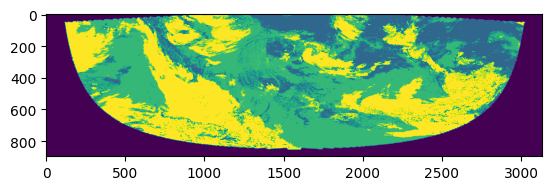

In [47]:
plt.imshow(remaped[10,:,:])